In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
for candidate in (PROJECT_ROOT, *PROJECT_ROOT.parents):
    if (candidate / "requirements.txt").is_file():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the project root (requirements.txt).")

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTION_DATA_DIR = PROJECT_ROOT / "data" / "prediction"
PREDICTIONS_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODELS_OUTPUT_DIR = PROJECT_ROOT / "models"
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [3]:
laide_data = pd.read_csv(PROCESSED_DATA_DIR / "NEW SVM-ET DATA.csv")

In [4]:
laide_data.head(40)

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,G/NG
0,6.512646,10.515026,1095.140015,12237.599610,8.100250,0.990786,0.000000,5.235600,1
1,6.522613,10.515026,661.468994,11191.099610,20.590401,0.990786,0.000000,2.100170,1
2,6.861486,10.921823,5303.720215,5606.160156,0.000000,0.000000,0.000000,3.945070,0
3,6.861486,10.931993,4832.799805,5963.270020,0.000000,0.000000,0.000000,0.928036,0
4,6.522613,10.555705,1773.050049,10772.099610,2.070660,0.990786,0.000000,1.640250,1
5,6.532579,10.555705,1543.430054,9690.400391,13.567900,0.990786,0.088839,1.912650,1
6,6.592381,10.870973,3293.659912,4570.540039,0.000000,0.000000,0.000000,1.640250,0
7,6.592381,10.881143,2480.159912,3720.209961,0.000000,0.724308,0.000000,1.640250,0
8,6.582414,10.667574,3659.419922,13393.500000,0.000000,0.077593,0.138519,1.766520,1
9,6.592381,10.667574,4710.660156,12895.799800,0.000000,0.990786,0.127088,4.194720,1


In [5]:
# Step 3 — Shuffle the dataset
laide_data = laide_data.sample(frac=1, random_state=42).reset_index(drop=True)

In [6]:
laide_data.head(40)

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,G/NG
0,6.672116,10.799784,5401.109863,13186.500000,0.000000,0.000000,0.000000,2.364900,0
1,6.512646,10.515026,1095.140015,12237.599610,8.100250,0.990786,0.000000,5.235600,1
2,6.692049,10.901483,881.981018,3119.169922,55.105400,0.978372,0.000000,1.640250,1
3,6.522613,10.555705,1773.050049,10772.099610,2.070660,0.990786,0.000000,1.640250,1
4,6.801685,10.952333,1322.969971,2019.050049,28.696600,0.780345,0.088665,0.656249,1
5,6.612314,10.962503,3595.840088,7991.770020,0.000000,0.000000,0.000000,2.561140,0
6,6.622281,10.840463,7924.850098,9358.000000,0.000000,0.000000,0.000000,1.352700,0
7,6.711983,10.840463,1475.750000,7610.009766,13.784000,0.000000,0.000000,2.703890,1
8,6.731917,10.891313,661.484985,1967.589966,51.017899,0.000000,0.000000,20.740801,1
9,6.582414,10.728594,6523.729981,19435.300780,0.000000,0.000000,0.171221,1.312330,1


In [7]:
XX = laide_data.drop("X", axis = 1, inplace = True)
YY = laide_data.drop("Y", axis = 1 , inplace = True)

In [8]:
laide_data.head()

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,G/NG
0,5401.109863,13186.500000,0.00000,0.000000,0.000000,2.364900,0
1,1095.140015,12237.599610,8.10025,0.990786,0.000000,5.235600,1
2,881.981018,3119.169922,55.10540,0.978372,0.000000,1.640250,1
3,1773.050049,10772.099610,2.07066,0.990786,0.000000,1.640250,1
4,1322.969971,2019.050049,28.69660,0.780345,0.088665,0.656249,1


Correlation of each feature with G/NG (descending):
LINEAMENT DENSITY    0.592572
HYDROTHERMAL         0.366576
SLOPE                0.277273
LITHOLOGY           -0.000606
LIN. INT            -0.531892
LINEAMENT           -0.636559
Name: G/NG, dtype: float64


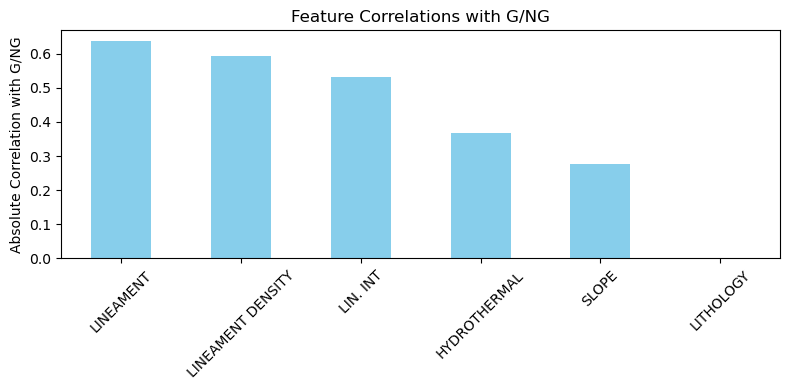

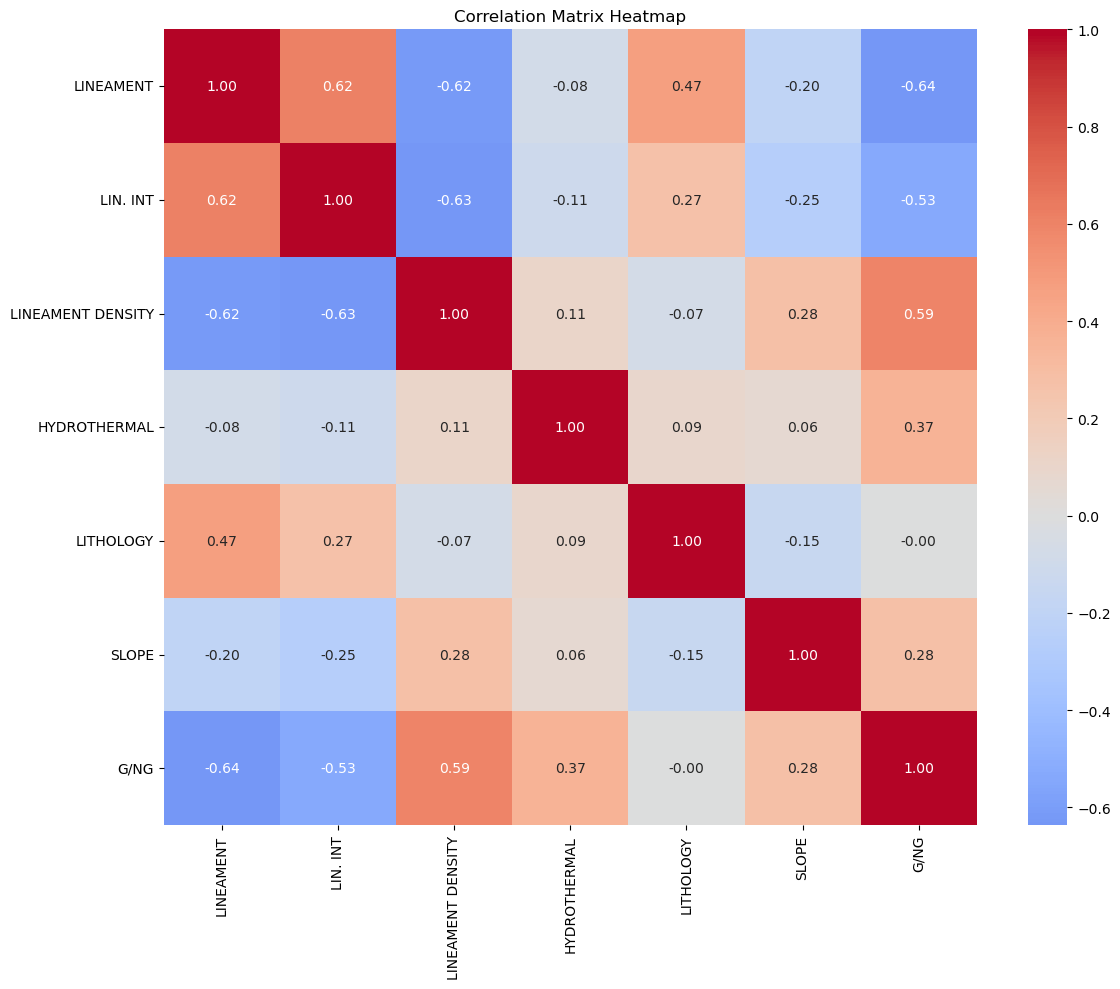

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# correlation matrix : This checks for relationship between data
corr = laide_data.corr()

# Print correlation values with GOLD
print("Correlation of each feature with G/NG (descending):")
corr_with_gold = corr['G/NG'].drop('G/NG').sort_values(ascending=False)
print(corr_with_gold)

# Bar plot of absolute correlations with GOLD
plt.figure(figsize=(8, 4))
corr_with_gold.abs().sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.ylabel('Absolute Correlation with G/NG')
plt.title('Feature Correlations with G/NG')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Full correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

In [17]:
laide_data.shape , laide_data.size

((70, 7), 490)

In [18]:
# Features and target
X = laide_data.drop('G/NG', axis=1) 
y = laide_data['G/NG']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [19]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and fit the SVR model
svr = SVR(kernel='rbf', C=0.1, epsilon=0.01)
svr.fit(X_train_scaled, y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,0.1
,epsilon,0.01
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [20]:
#  Predict continuous values
y_pred_continuous = svr.predict(X_test_scaled)

# Convert predictions to class labels
# For binary classification (0 & 1)
y_pred_class = (y_pred_continuous >= 0.5).astype(int)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class, zero_division=0)
recall = recall_score(y_test, y_pred_class, zero_division=0)
f1 = f1_score(y_test, y_pred_class, zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:\n", classification_report(y_test, y_pred_class, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_class))

Accuracy: 0.8571428571428571
Precision: 1.0
Recall: 0.7142857142857143
F1 Score: 0.8333333333333334

Classification Report:
               precision    recall  f1-score   support

           0       0.78      1.00      0.88         7
           1       1.00      0.71      0.83         7

    accuracy                           0.86        14
   macro avg       0.89      0.86      0.85        14
weighted avg       0.89      0.86      0.85        14

Confusion Matrix:
 [[7 0]
 [2 5]]


In [21]:
# Additional imports for tuning
import optuna
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Shuffle data
laide_data = laide_data.sample(frac=1, random_state=42).reset_index(drop=True)

# Features and target
X = laide_data.drop('G/NG', axis=1)
y = laide_data['G/NG']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define the Optuna objective function
def objective(trial):
    # Suggest a scaler
    scaler_choice = trial.suggest_categorical('scaler', ['standard', 'minmax', 'robust'])
    if scaler_choice == 'standard':
        scaler = StandardScaler()
    elif scaler_choice == 'minmax':
        scaler = MinMaxScaler()
    else:
        scaler = RobustScaler()

    # Scale features
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Suggest SVR parameters
    kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
    C = trial.suggest_loguniform('C', 0.1, 1000)
    epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
    gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])

    # Create and fit model
    model = SVR(kernel=kernel, C=C, epsilon=epsilon, gamma=gamma)
    model.fit(X_train_scaled, y_train)

    # Predict continuous values
    y_pred_cont = model.predict(X_test_scaled)

    # Convert to binary
    y_pred_class = (y_pred_cont >= 0.5).astype(int)

    # Return F1 score
    return f1_score(y_test, y_pred_class, zero_division=0)

# Create Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print("Best parameters:", study.best_params)
print("Best F1 score:", study.best_value)

# Apply best scaler
if study.best_params['scaler'] == 'standard':
    final_scaler = StandardScaler()
elif study.best_params['scaler'] == 'minmax':
    final_scaler = MinMaxScaler()
else:
    final_scaler = RobustScaler()

X_train_scaled = final_scaler.fit_transform(X_train)
X_test_scaled = final_scaler.transform(X_test)

# Train final model
final_params = {k: v for k, v in study.best_params.items() if k != 'scaler'}
final_model = SVR(**final_params)
final_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_cont = final_model.predict(X_test_scaled)
y_pred_class = (y_pred_cont >= 0.5).astype(int)

# Evaluation
print("\nFinal Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_class))
print("Precision:", precision_score(y_test, y_pred_class, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_class, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_class, zero_division=0))
print("\nClassification Report:\n", classification_report(y_test, y_pred_class, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_class))

[I 2025-08-16 11:23:01,620] A new study created in memory with name: no-name-621120f4-31ad-4869-8d0c-5eef2288094b
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  C = trial.suggest_loguniform('C', 0.1, 1000)
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:35: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
[I 2025-08-16 11:23:01,736] Trial 0 finished with value: 0.9333333333333333 and parameters: {'scaler': 'standard', 'kernel': 'rbf', 'C': 94.53194782035227, 'epsilon': 0.1290755051176839, 'gamma': 'auto'}. Best is trial 0 with value: 0.9333333333333333.
C:\Users\G\App

C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  C = trial.suggest_loguniform('C', 0.1, 1000)
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:35: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
[I 2025-08-16 11:23:02,734] Trial 10 finished with value: 0.8333333333333334 and parameters: {'scaler': 'robust', 'kernel': 'poly', 'C': 435.2213941437906, 'epsilon': 0.01735302820631783, 'gamma': 'scale'}. Best is trial 0 with value: 0.9333333333333333.
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0

C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  C = trial.suggest_loguniform('C', 0.1, 1000)
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:35: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
[I 2025-08-16 11:23:03,279] Trial 20 finished with value: 0.9333333333333333 and parameters: {'scaler': 'standard', 'kernel': 'rbf', 'C': 67.15428320196611, 'epsilon': 0.15027612868651832, 'gamma': 'auto'}. Best is trial 0 with value: 0.9333333333333333.
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0

C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  C = trial.suggest_loguniform('C', 0.1, 1000)
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:35: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
[I 2025-08-16 11:23:03,801] Trial 30 finished with value: 0.8333333333333334 and parameters: {'scaler': 'minmax', 'kernel': 'rbf', 'C': 48.15979420439834, 'epsilon': 0.19260178832145322, 'gamma': 'auto'}. Best is trial 0 with value: 0.9333333333333333.
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. 

C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  C = trial.suggest_loguniform('C', 0.1, 1000)
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:35: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  epsilon = trial.suggest_uniform('epsilon', 0.01, 1)
[I 2025-08-16 11:23:04,451] Trial 40 finished with value: 0.6666666666666666 and parameters: {'scaler': 'robust', 'kernel': 'poly', 'C': 569.4501372376301, 'epsilon': 0.5664064510107434, 'gamma': 'auto'}. Best is trial 0 with value: 0.9333333333333333.
C:\Users\G\AppData\Local\Temp\ipykernel_20612\170749829.py:34: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. 

[I 2025-08-16 11:23:04,958] Trial 49 finished with value: 0.5454545454545454 and parameters: {'scaler': 'minmax', 'kernel': 'poly', 'C': 2.552766650717074, 'epsilon': 0.052052073321602985, 'gamma': 'auto'}. Best is trial 0 with value: 0.9333333333333333.


Best parameters: {'scaler': 'standard', 'kernel': 'rbf', 'C': 94.53194782035227, 'epsilon': 0.1290755051176839, 'gamma': 'auto'}
Best F1 score: 0.9333333333333333

Final Model Evaluation:
Accuracy: 0.9285714285714286
Precision: 0.875
Recall: 1.0
F1 Score: 0.9333333333333333

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.86      0.92         7
           1       0.88      1.00      0.93         7

    accuracy                           0.93        14
   macro avg       0.94      0.93      0.93        14
weighted avg       0.94      0.93      0.93        14

Confusion Matrix:
 [[6 1]
 [0 7]]


In [24]:
# Threshold the predictions from SVR

# Add actual & predicted to test features
comparison_with_features = X_test.copy()
comparison_with_features['Actual'] = y_test.values
comparison_with_features['Predicted'] = y_pred_class

# Save to Excel
comparison_with_features.to_excel(PREDICTIONS_OUTPUT_DIR / "svr_test_data_predictions_comparison.xlsx", index=False)

# Preview
print(comparison_with_features.head(20))

       LINEAMENT      LIN. INT  LINEAMENT DENSITY  HYDROTHERMAL  LITHOLOGY  \
50   2480.159912   3720.209961           0.000000      0.724308   0.000000   
69   2010.810059  16869.400390           0.000000      0.000000   0.000000   
11   6523.729981  19435.300780           0.000000      0.000000   0.171221   
38    661.484985   1967.589966          51.017899      0.000000   0.000000   
67    220.496002    217.856003          54.825901      0.000000   0.109536   
25   7251.930176  10078.900390           0.000000      0.965770   0.000000   
9    4622.750000  18334.000000           0.000000      0.983706   0.000000   
20    309.981995   1710.069946          60.182999      0.990786   0.000000   
18   1763.959961   6177.700195           1.313830      0.000000   0.000000   
46    930.060974   1777.369995          40.290402      0.990786   0.000000   
10  11336.900390  13898.000000           0.000000      0.944826   0.172685   
5     619.966980   2986.840088          40.961700      0.000000 

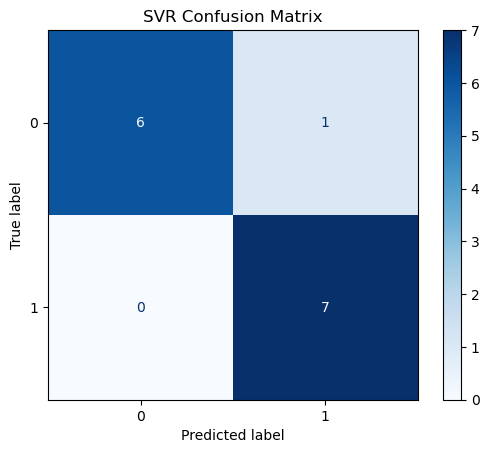

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_class)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='Blues', values_format='d')
plt.title('SVR Confusion Matrix')
plt.show()

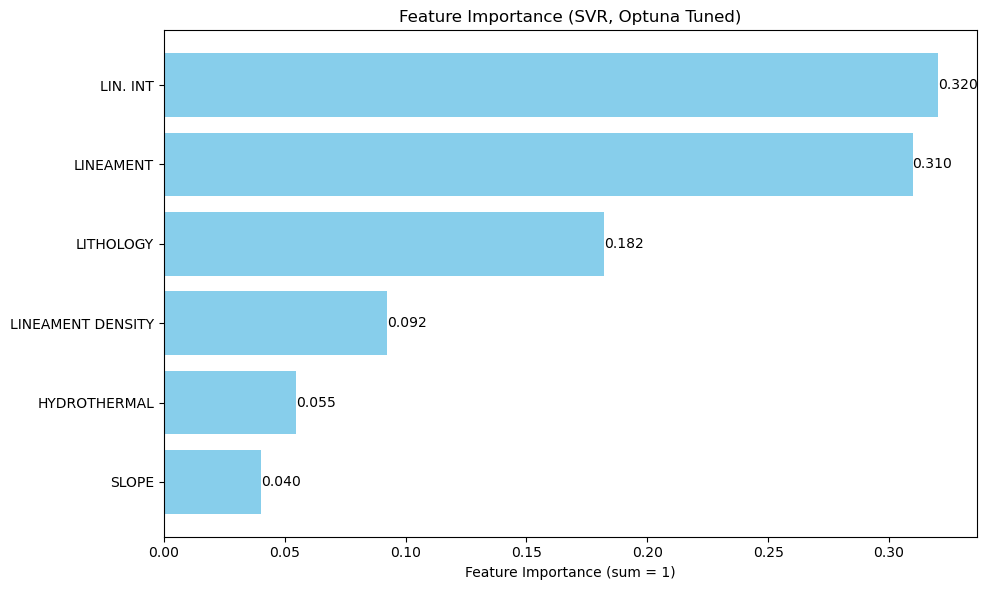

In [26]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd

# Compute permutation importance
perm_result = permutation_importance(
    final_model,
    X_test_scaled,
    y_test,
    scoring='r2',
    n_repeats=30,
    random_state=42
)

# Create DataFrame
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Raw Importance': perm_result.importances_mean
})

# Normalize absolute values so they sum to 1
importance_df['Normalized Importance'] = (
    importance_df['Raw Importance'].abs() / importance_df['Raw Importance'].abs().sum()
)

# Sort for plotting
importance_df = importance_df.sort_values(by='Normalized Importance', ascending=False)

# Plot normalized values
plt.figure(figsize=(10, 6))
bars = plt.barh(
    importance_df['Feature'],
    importance_df['Normalized Importance'],
    color='skyblue'
)
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance (sum = 1)')
plt.title('Feature Importance (SVR, Optuna Tuned)')

# Add value labels
for bar, norm_val in zip(bars, importance_df['Normalized Importance']):
    plt.text(norm_val, bar.get_y() + bar.get_height()/2, f'{norm_val:.3f}', va='center', ha='left')

plt.tight_layout()
plt.show()

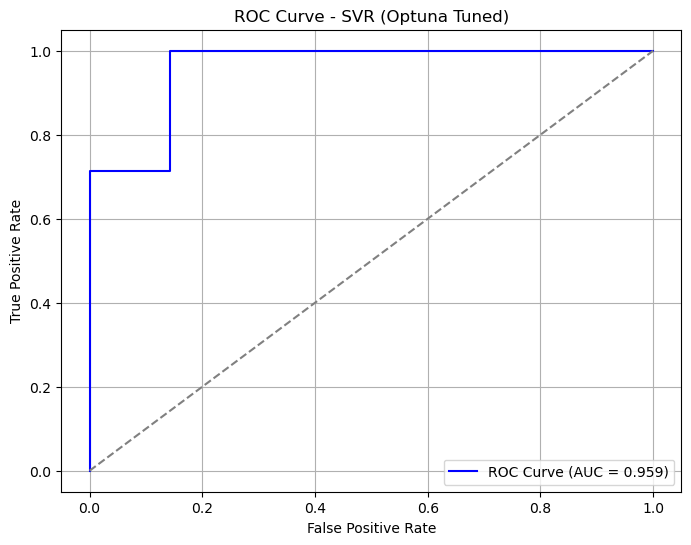

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Use continuous predictions (before thresholding)
y_scores = final_model.predict(X_test_scaled)

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal baseline
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVR (Optuna Tuned)')
plt.legend()
plt.grid(True)
plt.show()

In [28]:
#let us save our model
import joblib

# Save model
joblib.dump(final_model, MODELS_OUTPUT_DIR / "SVR_Laide_Gold_final_model.pkl")

['SVR_Laide_Gold_final_model.pkl']

In [3]:
# Load model later
import joblib
laide_SVR_model = joblib.load(MODELS_OUTPUT_DIR / "SVR_Laide_Gold_final_model.pkl")

In [47]:
validation_gold_data = pd.read_csv(PROCESSED_DATA_DIR / "RESEARCH DATA.csv")
validation_gold_data.head()

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,FID
0,6.502679,10.504856,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,0
1,6.512646,10.504856,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1
2,6.522613,10.504856,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,2
3,6.532579,10.504856,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,3
4,6.542546,10.504856,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,4


In [48]:
XXX = validation_gold_data["X"]
YYY = validation_gold_data["Y"]
FID = validation_gold_data["FID"]
validation_gold_data.drop("X", axis = 1, inplace = True)
validation_gold_data.drop("Y", axis = 1, inplace = True)
validation_gold_data.drop("FID", axis = 1, inplace = True)
validation_gold_data.fillna(0, inplace=True)

In [49]:
validation_gold_data.head(20)

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840
5,1098.349976,8303.509766,21.434300,-9999.000000,0.080558,3.342580
6,1406.130005,7214.259766,7.887690,0.990786,0.073581,3.374490
7,900.247986,6125.640137,11.297700,0.990786,0.064622,10.697600
8,0.000000,5038.060059,21.886900,0.990786,0.054030,3.736060
9,620.416016,3952.370117,29.390801,0.990786,0.041124,1.312330


In [50]:
# If predictions are floats
predicted_gold = laide_SVR_model.predict(validation_gold_data)

# Threshold to get 0 or 1
predicted_gold_binary = (predicted_gold >= 0.5).astype(int)

C:\Users\G\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVR was fitted without feature names
  warnings.warn(


In [51]:
validation_gold_data["SVM_predicted_gold_binary"] = predicted_gold_binary

In [52]:
validation_gold_data.head(100)

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,SVM_predicted_gold_binary
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,1
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,1
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,1
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,1
...,...,...,...,...,...,...,...
95,792.453003,3900.459961,34.461498,0.983706,0.000000,1.968060,1
96,440.979004,3120.689941,37.145100,-9999.000000,0.000000,3.619590,1
97,0.000000,2577.639893,38.266602,-9999.000000,0.000000,6.001780,1
98,220.490005,2435.179932,33.305199,-9999.000000,0.000000,6.888710,1


In [53]:
validation_gold_data["X"] = XXX
validation_gold_data["Y"] = YYY

In [54]:
validation_gold_data.head()

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,SVM_predicted_gold_binary,X,Y
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,1,6.502679,10.504856
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1,6.512646,10.504856
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,1,6.522613,10.504856
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,1,6.532579,10.504856
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,1,6.542546,10.504856


In [55]:
validation_gold_data.to_excel(PREDICTIONS_OUTPUT_DIR / "SVM_gold_predictions.xlsx", index=False)

print("Data saved to Svm_gold_predictions.xlsx")

Data saved to Svm_gold_predictions.xlsx


In [4]:
Gold_prediction = pd.read_csv(PREDICTION_DATA_DIR / "TO BE PREDICTED.csv")
Gold_prediction.head()

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE
0,6.981089,10.545535,792.434998,908.546021,28.243200,-9999.000000,0,3.835030
1,6.901354,10.565875,488.871002,4628.890137,36.017399,-9999.000000,0,4.985450
2,6.901354,10.576045,983.987000,4602.479981,17.130899,-9999.000000,0,0.328135
3,6.781751,10.586215,6978.629883,9383.030273,0.000000,0.990786,0,4.687750
4,6.761817,10.535365,6821.100098,9067.440430,0.000000,0.990786,0,2.200140


In [6]:
XG = Gold_prediction["X"]
YG = Gold_prediction["Y"]
Gold_prediction.drop("X", axis = 1, inplace = True)
Gold_prediction.drop("Y", axis = 1, inplace = True)

In [7]:
# If predictions are floats
predicted_gold1 = laide_SVR_model.predict(Gold_prediction)

# Threshold to get 0 or 1
predicted_gold_binary1 = (predicted_gold1 >= 0.5).astype(int)

C:\Users\G\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SVR was fitted without feature names
  warnings.warn(


In [8]:
Gold_prediction["SVM_predicted_gold_binary"] = predicted_gold_binary1

In [13]:
Gold_prediction["X"] = XG
Gold_prediction["Y"] = YG
Gold_prediction.head(11)

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,SVM_predicted_gold_binary,X,Y
0,792.434998,908.546021,28.243200,-9999.000000,0,3.835030,1,6.981089,10.545535
1,488.871002,4628.890137,36.017399,-9999.000000,0,4.985450,1,6.901354,10.565875
2,983.987000,4602.479981,17.130899,-9999.000000,0,0.328135,1,6.901354,10.576045
3,6978.629883,9383.030273,0.000000,0.990786,0,4.687750,1,6.781751,10.586215
4,6821.100098,9067.440430,0.000000,0.990786,0,2.200140,1,6.761817,10.535365
5,7904.140137,9955.669922,0.000000,0.990786,0,2.295740,1,6.771784,10.535365
6,4415.240234,5919.310059,0.000000,0.990786,0,3.958610,1,6.871453,10.687914
7,3117.550049,13463.599610,0.000000,0.543121,0,3.483870,1,6.961155,10.698084
8,1710.040039,5969.319824,3.327570,0.990786,0,3.277810,1,6.532579,10.982842
9,1864.140015,7069.310059,0.732963,0.990786,0,1.766520,1,6.532579,10.993012


In [14]:
Gold_prediction.to_excel(PREDICTIONS_OUTPUT_DIR / "SVM_gold_predictions for To be Predicted.xlsx", index=False)

print("Data saved to SVM_gold_predictions for To be Predicted.xlsx")

Data saved to SVM_gold_predictions for To be Predicted.xlsx


# Now let us use EXTRA TREE

In [15]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [57]:
# 1. Split (only if not done earlier)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Initialize Extra Trees Classifier
extra_trees = ExtraTreesClassifier(n_estimators=100, random_state=42)

# 3. Fit the model
extra_trees.fit(X_train, y_train)

# 4. Predict
y_pred = extra_trees.predict(X_test)

# 5. Evaluate
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.88      0.82         8
           1       0.80      0.67      0.73         6

    accuracy                           0.79        14
   macro avg       0.79      0.77      0.78        14
weighted avg       0.79      0.79      0.78        14

Confusion Matrix:
[[7 1]
 [2 4]]


In [58]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import ExtraTreesClassifier
import optuna

def objective(trial):
    # Wider but controlled search space
    n_estimators = trial.suggest_int("n_estimators", 50, 500, step=50)
    max_depth = trial.suggest_int("max_depth", 3, 50)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", None])
    min_samples_split = trial.suggest_int("min_samples_split", 2, 30)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    criterion = trial.suggest_categorical("criterion", ["gini", "entropy"])
    bootstrap = trial.suggest_categorical("bootstrap", [True, False])

    # Model
    model = ExtraTreesClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        max_features=max_features,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        criterion=criterion,
        bootstrap=bootstrap,
        random_state=42
    )

    # Stratified K-Fold for small dataset
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    return scores.mean()

# Run optimization
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=80, show_progress_bar=True)

# Best parameters & accuracy
print("Best parameters:", study.best_params)
print("Best accuracy:", study.best_value)

# Train final model
best_model = ExtraTreesClassifier(**study.best_params, random_state=42)
best_model.fit(X_train, y_train)

[I 2025-08-16 11:37:51,012] A new study created in memory with name: no-name-ef23b078-30d4-47b5-9220-6d685369c14f


  0%|          | 0/80 [00:00<?, ?it/s]

[I 2025-08-16 11:37:55,444] Trial 0 finished with value: 0.840909090909091 and parameters: {'n_estimators': 400, 'max_depth': 30, 'max_features': None, 'min_samples_split': 22, 'min_samples_leaf': 5, 'criterion': 'entropy', 'bootstrap': False}. Best is trial 0 with value: 0.840909090909091.
[I 2025-08-16 11:37:59,479] Trial 1 finished with value: 0.8045454545454545 and parameters: {'n_estimators': 300, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 5, 'min_samples_leaf': 7, 'criterion': 'gini', 'bootstrap': True}. Best is trial 0 with value: 0.840909090909091.
[I 2025-08-16 11:38:04,013] Trial 2 finished with value: 0.806060606060606 and parameters: {'n_estimators': 450, 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_split': 25, 'min_samples_leaf': 11, 'criterion': 'entropy', 'bootstrap': False}. Best is trial 0 with value: 0.840909090909091.
[I 2025-08-16 11:38:06,076] Trial 3 finished with value: 0.8575757575757577 and parameters: {'n_estimators': 150, 'max_dept

[I 2025-08-16 11:39:16,732] Trial 29 finished with value: 0.8424242424242424 and parameters: {'n_estimators': 100, 'max_depth': 7, 'max_features': 'log2', 'min_samples_split': 23, 'min_samples_leaf': 5, 'criterion': 'gini', 'bootstrap': False}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:39:21,668] Trial 30 finished with value: 0.8227272727272729 and parameters: {'n_estimators': 500, 'max_depth': 36, 'max_features': None, 'min_samples_split': 16, 'min_samples_leaf': 9, 'criterion': 'gini', 'bootstrap': False}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:39:24,392] Trial 31 finished with value: 0.840909090909091 and parameters: {'n_estimators': 250, 'max_depth': 24, 'max_features': None, 'min_samples_split': 8, 'min_samples_leaf': 2, 'criterion': 'gini', 'bootstrap': False}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:39:26,571] Trial 32 finished with value: 0.840909090909091 and parameters: {'n_estimators': 200, 'max_dep

[I 2025-08-16 11:40:42,717] Trial 58 finished with value: 0.5181818181818182 and parameters: {'n_estimators': 200, 'max_depth': 38, 'max_features': None, 'min_samples_split': 27, 'min_samples_leaf': 20, 'criterion': 'entropy', 'bootstrap': True}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:40:45,741] Trial 59 finished with value: 0.8227272727272729 and parameters: {'n_estimators': 300, 'max_depth': 28, 'max_features': None, 'min_samples_split': 5, 'min_samples_leaf': 3, 'criterion': 'gini', 'bootstrap': False}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:40:48,400] Trial 60 finished with value: 0.8575757575757577 and parameters: {'n_estimators': 200, 'max_depth': 46, 'max_features': 'sqrt', 'min_samples_split': 12, 'min_samples_leaf': 1, 'criterion': 'gini', 'bootstrap': True}. Best is trial 26 with value: 0.8772727272727273.
[I 2025-08-16 11:40:51,651] Trial 61 finished with value: 0.8575757575757577 and parameters: {'n_estimators': 250, 'ma

,n_estimators,100
,criterion,'gini'
,max_depth,39
,min_samples_split,4
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [59]:
# Threshold the predictions from ETC
y_pred_binary = (y_pred >= 0.5).astype(int)

# Add actual & predicted to test features
comparison_with_features = X_test.copy()
comparison_with_features['Actual'] = y_test.values
comparison_with_features['Predicted'] = y_pred_binary

# Save to Excel
comparison_with_features.to_excel(PREDICTIONS_OUTPUT_DIR / "ETC_test_data_predictions_comparison.xlsx", index=False)

# Preview
print(comparison_with_features.head(20))

       LINEAMENT      LIN. INT  LINEAMENT DENSITY  HYDROTHERMAL  LITHOLOGY  \
22   6408.640137  17546.500000           0.000000      0.000000   0.000000   
0   11314.000000  12631.700200           0.000000      0.000000   0.000000   
49   2195.800049   6261.939941           0.000000      0.990786   0.000000   
4    4458.479981  13225.200200           0.000000      0.000000   0.000000   
54      0.000000   3550.889893          57.923801      0.990786   0.000000   
18   1763.959961   6177.700195           1.313830      0.000000   0.000000   
10  11336.900390  13898.000000           0.000000      0.944826   0.172685   
33   3659.419922  13393.500000           0.000000      0.077593   0.138519   
45   1405.689941   7838.080078           6.261470      0.884511   0.000000   
12   3083.469971  17781.500000           0.000000      0.000000   0.000000   
31   3805.020020  13462.200200           0.000000      0.000000   0.000000   
9    4622.750000  18334.000000           0.000000      0.983706 

📊 Model Evaluation Metrics
Accuracy       : 0.7143
Precision      : 0.7143
Recall         : 0.7143
F1 Score       : 0.7143
ROC AUC        : 0.9167


<Figure size 600x500 with 0 Axes>

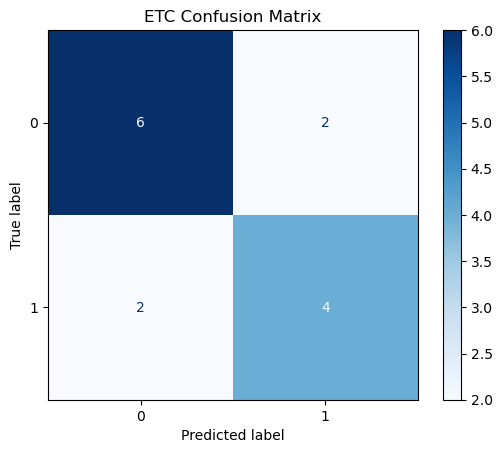

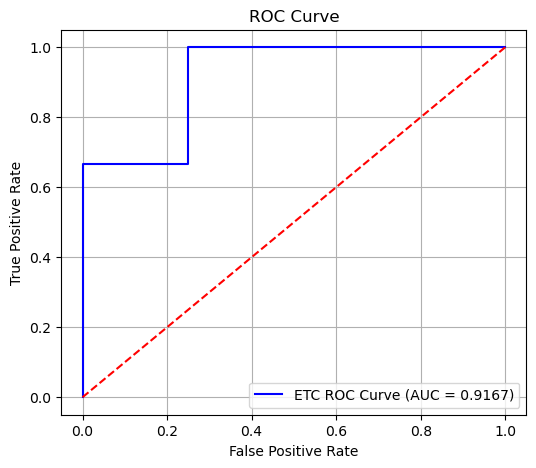

In [60]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
import matplotlib.pyplot as plt

# Predictions
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1] if len(best_model.classes_) == 2 else None

# Metrics
print("📊 Model Evaluation Metrics")
print(f"Accuracy       : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision      : {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall         : {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1 Score       : {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

if y_proba is not None:
    print(f"ROC AUC        : {roc_auc_score(y_test, y_proba):.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

plt.figure(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("ETC Confusion Matrix")
plt.show()

# ROC Curve (only for binary classification)
if y_proba is not None:
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color="blue", label=f"ETC ROC Curve (AUC = {roc_auc_score(y_test, y_proba):.4f})")
    plt.plot([0, 1], [0, 1], color="red", linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

             Feature  Importance
0          LINEAMENT    0.362016
2  LINEAMENT DENSITY    0.207419
3       HYDROTHERMAL    0.158471
1           LIN. INT    0.155724
4          LITHOLOGY    0.063636
5              SLOPE    0.052734


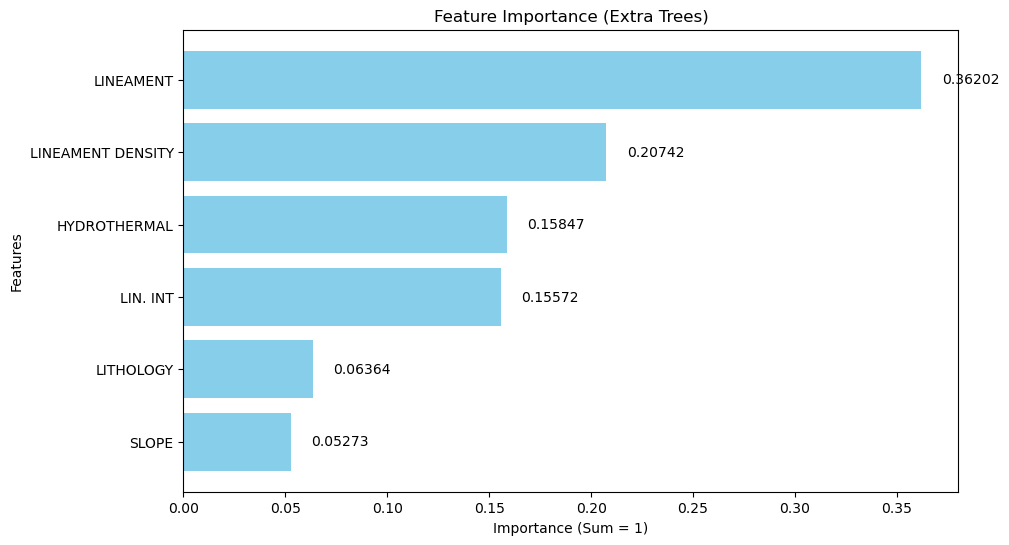

In [61]:
# Get raw importances
importances = best_model.feature_importances_

# Normalize so sum equals 1
importances_normalized = importances / np.sum(importances)

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances_normalized
}).sort_values(by="Importance", ascending=False)

# Print table
print(feature_importance_df)

# Plot
plt.figure(figsize=(10, 6))
bars = plt.barh(feature_importance_df["Feature"], feature_importance_df["Importance"], color="skyblue")
plt.xlabel("Importance (Sum = 1)")
plt.ylabel("Features")
plt.title("Feature Importance (Extra Trees)")
plt.gca().invert_yaxis()

# Add value labels to the bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.5f}', va='center')

plt.show()

In [62]:
#let us save ETC our model
import joblib

# Save model
joblib.dump(best_model, MODELS_OUTPUT_DIR / "ETC_Laide_Gold_final_model.pkl")

['ETC_Laide_Gold_final_model.pkl']

In [16]:
# Load model later
laide_ETC_model = joblib.load(MODELS_OUTPUT_DIR / "ETC_Laide_Gold_final_model.pkl")

In [64]:
validation_gold_data1 = pd.read_csv(PROCESSED_DATA_DIR / "RESEARCH DATA.csv")
validation_gold_data1.head()

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,FID
0,6.502679,10.504856,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,0
1,6.512646,10.504856,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1
2,6.522613,10.504856,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,2
3,6.532579,10.504856,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,3
4,6.542546,10.504856,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,4


In [65]:
XXX = validation_gold_data1["X"]
YYY = validation_gold_data1["Y"]
FID = validation_gold_data1["FID"]
validation_gold_data1.drop("X", axis = 1, inplace = True)
validation_gold_data1.drop("Y", axis = 1, inplace = True)
validation_gold_data1.drop("FID", axis = 1, inplace = True)

In [66]:
validation_gold_data1.head()

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840


In [67]:
predicted_gold1 = laide_ETC_model.predict(validation_gold_data1)

# Threshold to get 0 or 1
predicted_gold_binary1 = (predicted_gold1 >= 0.5).astype(int)

In [68]:
validation_gold_data1["ETC_predicted_gold_binary"] = predicted_gold_binary

In [69]:
validation_gold_data1.head(20)

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,ETC_predicted_gold_binary
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,1
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,1
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,1
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,1
5,1098.349976,8303.509766,21.434300,-9999.000000,0.080558,3.342580,1
6,1406.130005,7214.259766,7.887690,0.990786,0.073581,3.374490,1
7,900.247986,6125.640137,11.297700,0.990786,0.064622,10.697600,1
8,0.000000,5038.060059,21.886900,0.990786,0.054030,3.736060,1
9,620.416016,3952.370117,29.390801,0.990786,0.041124,1.312330,1


In [70]:
validation_gold_data1["X"] = XXX
validation_gold_data1["Y"] = YYY

In [71]:
validation_gold_data1.head()

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,ETC_predicted_gold_binary,X,Y
0,2012.750000,13607.700200,0.000000,0.990786,0.000000,1.766520,1,6.502679,10.504856
1,977.895019,12580.599610,8.212390,0.990786,0.000000,0.733701,1,6.512646,10.504856
2,440.979004,11565.200200,19.063900,0.990786,0.000000,4.985450,1,6.522613,10.504856
3,620.416016,10483.099610,29.549601,0.990786,0.000000,2.643660,1,6.532579,10.504856
4,881.958008,9393.179688,33.789501,-9999.000000,0.083702,5.560840,1,6.542546,10.504856


In [131]:
validation_gold_data1.to_excel(PREDICTIONS_OUTPUT_DIR / "ETC_gold_predictions.xlsx", index=False)

print("Data saved to ETC_gold_predictions.xlsx")

Data saved to ETC_gold_predictions.xlsx


In [17]:
Gold_prediction_ET = pd.read_csv(PREDICTION_DATA_DIR / "TO BE PREDICTED.csv")
Gold_prediction_ET.head()

,X,Y,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE
0,6.981089,10.545535,792.434998,908.546021,28.243200,-9999.000000,0,3.835030
1,6.901354,10.565875,488.871002,4628.890137,36.017399,-9999.000000,0,4.985450
2,6.901354,10.576045,983.987000,4602.479981,17.130899,-9999.000000,0,0.328135
3,6.781751,10.586215,6978.629883,9383.030273,0.000000,0.990786,0,4.687750
4,6.761817,10.535365,6821.100098,9067.440430,0.000000,0.990786,0,2.200140


In [18]:
XG = Gold_prediction_ET["X"]
YG = Gold_prediction_ET["Y"]
Gold_prediction_ET.drop("X", axis = 1, inplace = True)
Gold_prediction_ET.drop("Y", axis = 1, inplace = True)

In [21]:
# If predictions are floats
predicted_gold2 = laide_ETC_model.predict(Gold_prediction_ET)

# Threshold to get 0 or 1
predicted_gold_binary2 = (predicted_gold2 >= 0.5).astype(int)

In [22]:
Gold_prediction_ET["ETC_predicted_gold_binary"] = predicted_gold_binary2

In [23]:
Gold_prediction_ET["X"] = XG
Gold_prediction_ET["Y"] = YG
Gold_prediction_ET.head(11)

,LINEAMENT,LIN. INT,LINEAMENT DENSITY,HYDROTHERMAL,LITHOLOGY,SLOPE,ETC_predicted_gold_binary,X,Y
0,792.434998,908.546021,28.243200,-9999.000000,0,3.835030,1,6.981089,10.545535
1,488.871002,4628.890137,36.017399,-9999.000000,0,4.985450,1,6.901354,10.565875
2,983.987000,4602.479981,17.130899,-9999.000000,0,0.328135,1,6.901354,10.576045
3,6978.629883,9383.030273,0.000000,0.990786,0,4.687750,0,6.781751,10.586215
4,6821.100098,9067.440430,0.000000,0.990786,0,2.200140,0,6.761817,10.535365
5,7904.140137,9955.669922,0.000000,0.990786,0,2.295740,0,6.771784,10.535365
6,4415.240234,5919.310059,0.000000,0.990786,0,3.958610,0,6.871453,10.687914
7,3117.550049,13463.599610,0.000000,0.543121,0,3.483870,0,6.961155,10.698084
8,1710.040039,5969.319824,3.327570,0.990786,0,3.277810,1,6.532579,10.982842
9,1864.140015,7069.310059,0.732963,0.990786,0,1.766520,1,6.532579,10.993012


In [24]:
Gold_prediction_ET.to_excel(PREDICTIONS_OUTPUT_DIR / "ETC_gold_predictions for To be Predicted.xlsx", index=False)

print("Data saved to ETC_gold_predictions for To be Predicted.xlsx")

Data saved to ETC_gold_predictions for To be Predicted.xlsx
